In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb
import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42

In [2]:
## Gradient descent

lr=0.01
tol = 0.0001

## Gradient descent in eta coordinates
def gd(eta_train, z_train, w):
    L = (w@np.clip(eta_train, hmin, hmax)-z_train)**2
    while L > tol :
        phi_dir = np.zeros(2)
        phi_dir[(eta_train>hmin) &(eta_train<hmax)] = 1
        grad = 2*(w@np.clip(eta_train, hmin, hmax)-z_train)*w*phi_dir
        eta_train = eta_train- lr*grad
        L = (w@np.clip(eta_train, hmin, hmax)-z_train)**2
    return(eta_train)

## Gradient descent in u coordinates
def gd_u(u_train,x_train, z_train, w):
    eta_train = u_train@x_train
    L = (w@np.clip(eta_train, hmin, hmax)-z_train)**2
    while L > tol :
        eta_train = u_train@x_train
        phi_dir = np.zeros(2)
        phi_dir[(eta_train>hmin) &(eta_train<hmax)] = 1
        grad = (2*(w@np.clip(eta_train, hmin, hmax)-z_train)*w*phi_dir)[:,None]@(x_train[None,:])
        u_train = u_train- lr*grad
        L = (w@np.clip(u_train@x_train, hmin, hmax)-z_train)**2
    return(u_train)



In [3]:
## Plot error countours

w1 = 1
w2 = 1
alpha = 5

def error_heatmap_plotter(z, eta_all, ax):
    errs = np.zeros((100,100))
    
    for i in range(0, 100):
        for j in range(0, 100):
            eta1 = eta_all[i]
            eta2 = eta_all[j]
            errs[i,j] = w1*np.clip(eta1,0, alpha) + w2*np.clip(eta2, 0, alpha)-z     
   
    cs = ax.contourf(eta_all, eta_all, abs(errs), levels = 15,cmap ='gray', rasterized = True)
    ax.set_aspect('equal')
    ax.tick_params(axis='both', which='major', labelsize=15)
    ax.set_yticks([-5,0,5,10])
    cbar = fig.colorbar(cs)
    ax.plot()


def error_heatmap_plotter_u(z, u_all, x, ax):
    errs = np.zeros((100,100))
    for i in range(0, 100):
        for j in range(0, 100):
            u1 = u_all[i]
            u2 = u_all[j]
            errs[i,j] = w1*np.clip(u1*x[0] + u2*x[1],0, alpha)- z
            
    cs = ax.contourf(u_all, u_all, abs(errs), levels = 15,cmap ='gray', rasterized = True)
    ax.set_aspect('equal')
    ax.tick_params(axis='both', which='major', labelsize=15)
    ax.set_yticks([-5,0,5,10])
    cbar = fig.colorbar(cs)
    ax.plot()

[4. 2.]
u after gd
[[-2. -4.]
 [20. 18.]]
u after gd
[[-6. -2.]
 [10.  6.]]


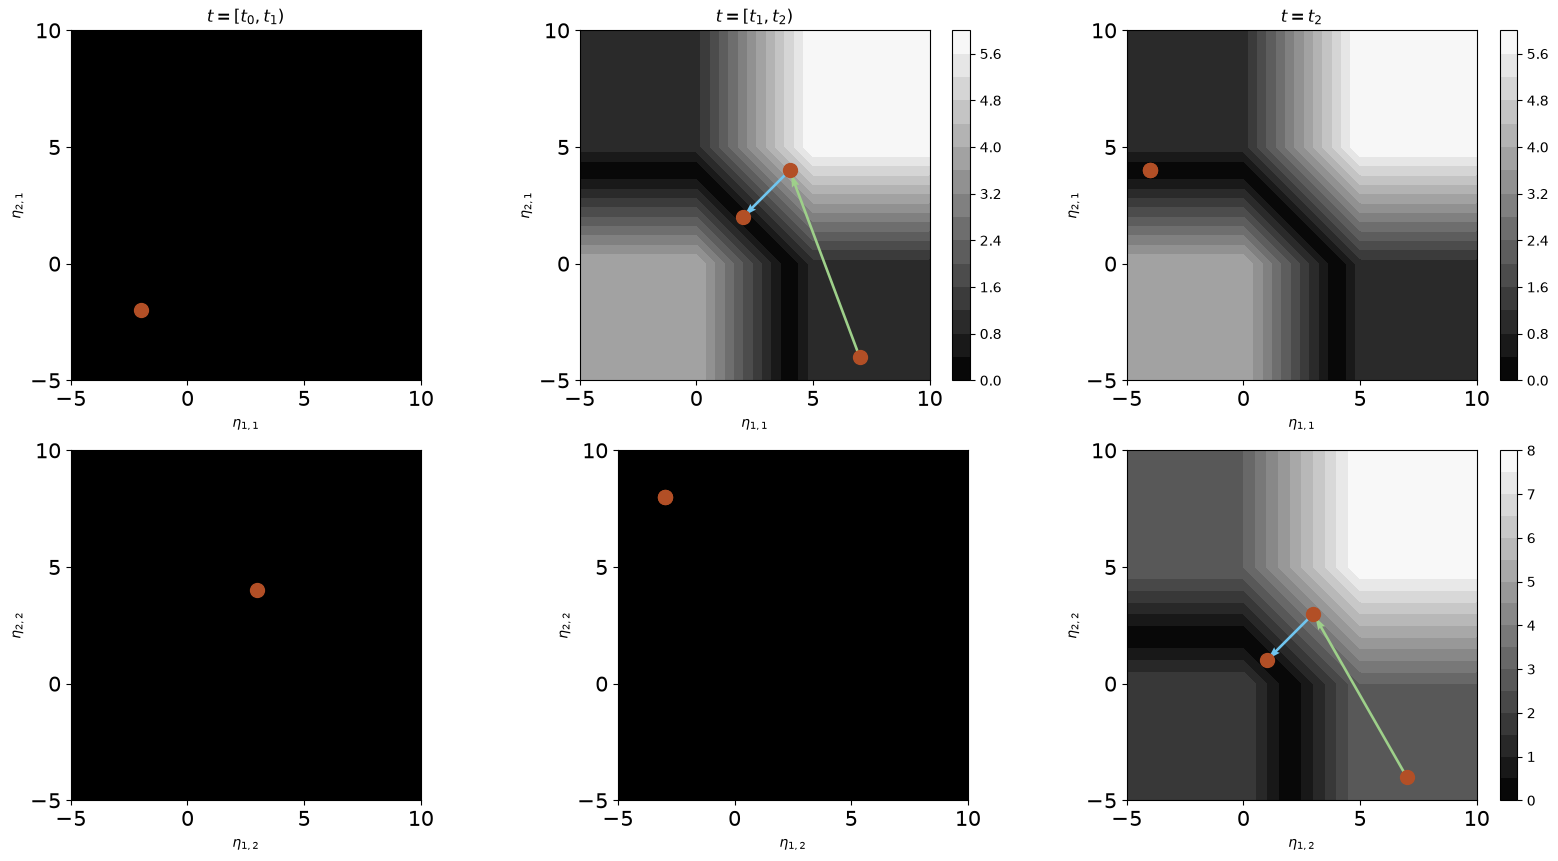

In [4]:
fig, axs = plt.subplots(2,3, figsize = (20, 10))

hmin = 0
hmax = 5
markersize = 10
point_color = '#B24F26'
allocation_color = '#9ED08A'
learning_color = '#70C5EF'
w = np.array([1,1])


u_T = np.array([[4,4],[3,-1]])
x = np.array([[1,-0.5],[-1,1]])
z = w@np.clip(u_T@x, hmin, hmax)
print(z)

u_all = np.linspace(-5,10, 100)
error_heatmap_plotter(z[0], u_all, axs[0,1])
error_heatmap_plotter(z[0], u_all, axs[0,2])
error_heatmap_plotter(z[1], u_all, axs[1,2])

eta = np.array([[-2,3],[-2,4]],dtype=float)
axs[0,0].plot(eta[0,0], eta[1,0],'o',markersize=markersize, color= point_color)
axs[1,0].plot(eta[0,1], eta[1,1],'o',markersize=markersize, color= point_color)
axs[0,0].fill([-5,-5,10,10], [-5,10,10,-5], color = 'black') 
axs[1,0].fill([-5,-5,10,10], [-5,10,10,-5], color = 'black') 


## after drift
eta = np.array([[7,-3],[-4,8]],dtype=float)
eta_drift = eta.copy()
axs[0,1].plot(eta_drift[0,0], eta_drift[1,0],'o',markersize=markersize, color= point_color)
axs[1,1].plot(eta_drift[0,1], eta_drift[1,1],'o',markersize=markersize, color= point_color)
axs[1,1].fill([-5,-5,10,10], [-5,10,10,-5], color = 'black') 

## allocation
eta[:,0] = np.array([4,4])
axs[0,1].quiver(eta_drift[0,0], eta_drift[1,0], eta[0,0]-eta_drift[0,0], eta[1,0]-eta_drift[1,0],angles='xy', scale_units='xy', scale=1.02,color=allocation_color)
axs[0,1].plot(eta[0,0], eta[1,0],'o',markersize=markersize, color =point_color )
axs[1,1].plot(eta[0,1], eta[1,1],'o',markersize=markersize, color = point_color)

## gd in eta
eta_train = eta[:,0]
z_train = z[0]
eta_new = gd(eta_train, z_train, w)
axs[0,1].quiver(eta[0,0], eta[1,0], eta_new[0]-eta[0,0], eta_new[1]-eta[1,0],angles='xy', scale_units='xy', scale=1.02,color=learning_color)
eta[:,0] = eta_new

u = eta@np.linalg.inv(x)
print('u after gd')
print(np.round(u,1))


axs[0,1].plot(eta[0,0], eta[1,0],'o',markersize=markersize,color = point_color)
axs[1,1].plot(eta[0,1], eta[1,1],'o',markersize=markersize,color = point_color)

## after drift
eta = np.array([[-4,7],[4,-4]], dtype =float)
eta_drift = eta.copy()
axs[0,2].plot(eta_drift[0,0], eta_drift[1,0],'o',  markersize=markersize, color = point_color)
axs[1,2].plot(eta_drift[0,1], eta_drift[1,1],'o',markersize=markersize, color = point_color)

## allocation
eta[:,1] = np.array([3,3], dtype = float)
axs[1,2].quiver(eta_drift[0,1], eta_drift[1,1], eta[0,1]-eta_drift[0,1], eta[1,1]-eta_drift[1,1],angles='xy', scale_units='xy', scale=1.02,color=allocation_color)
axs[0,2].plot(eta[0,0], eta[1,0],'o',markersize=markersize, color = point_color)
axs[1,2].plot(eta[0,1], eta[1,1],'o',markersize=markersize, color = point_color)

u = eta@np.linalg.inv(x)
copy_u = u.copy()

## gd in eta
eta_train = eta[:,1]
z_train = z[1]
eta_new = gd(eta_train, z_train, w)
axs[1,2].quiver(eta[0,1], eta[1,1], eta_new[0]-eta[0,1], eta_new[1]-eta[1,1],angles='xy', scale_units='xy', scale=1.02,color=learning_color)
eta[:,1] = eta_new
u = eta@np.linalg.inv(x)
print('u after gd')
print(np.round(u,1))

eta_store_pic = eta[:,0].copy()
axs[0,2].plot(eta[0,0], eta[1,0],'o',  markersize=markersize,color = point_color)
axs[1,2].plot(eta[0,1], eta[1,1],'o',  markersize=markersize,color = point_color)

for currax in [axs[0,0],axs[1,0], axs[1,1]]:
    currax.set_aspect('equal')
    currax.set_xlim(-5,10)
    currax.set_ylim(-5,10)
    currax.set_xticks([-5,0,5,10])
    currax.set_yticks([-5,0,5,10])
    currax.tick_params(axis='both', which='major', labelsize=15)

axs[0,0].set_title(r'$t= [t_0, t_1)$')
axs[0,1].set_title(r'$t= [t_1, t_2)$')
axs[0,2].set_title(r'$t= t_2$')
for currax in [axs[0,0], axs[0,1], axs[0,2]]:
    currax.set_xlabel(r'$\eta_{1,1}$')
    currax.set_ylabel(r'$\eta_{2,1}$')

for currax in [axs[1,0], axs[1,1], axs[1,2]]:
    currax.set_xlabel(r'$\eta_{1,2}$')
    currax.set_ylabel(r'$\eta_{2,2}$')
##plt.savefig('../FIGURES/fig5_toy_example_cl_gd_eta.pdf', format='pdf', dpi=500)

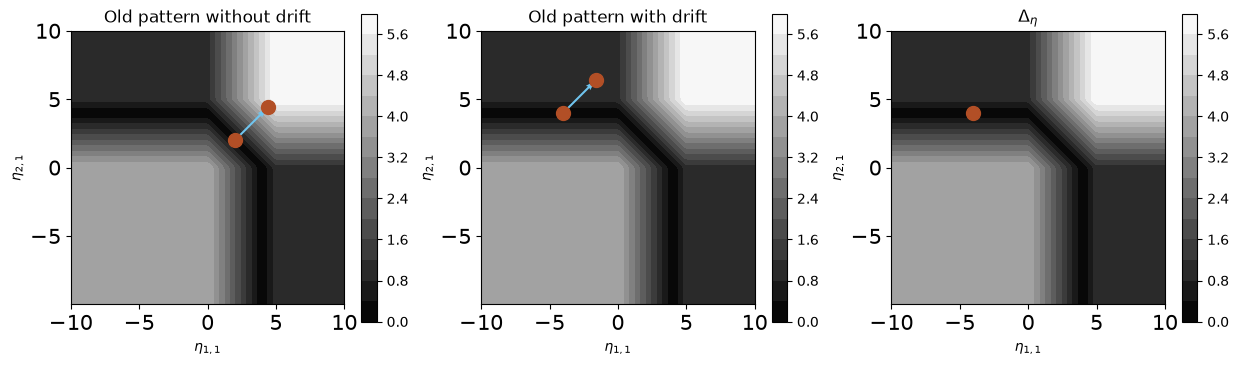

In [5]:
fig, axs = plt.subplots(1,3, figsize = (15, 4))

eta_all = np.linspace(-10,10, 100)
error_heatmap_plotter(z[0], eta_all, axs[0] )
error_heatmap_plotter(z[0], eta_all, axs[1])
error_heatmap_plotter(z[0], eta_all, axs[2])

## without drift
eta = np.array([[2,3], [2,3]])
eta_no_drift_bef = eta.copy()
u = eta@np.linalg.inv(x)
axs[0].plot(eta[0,0], eta[1,0],'o',  markersize=markersize,color = point_color)


x_train = x[:,1]
z_train = z[1]
u = gd_u(u,x_train, z_train, w)
eta = u@x
axs[0].plot(eta[0,0], eta[1,0],'o',  markersize=markersize,color = point_color)
axs[0].quiver(eta_no_drift_bef[0,0], eta_no_drift_bef[1,0], eta[0,0]-eta_no_drift_bef[0,0], eta[1,0]-eta_no_drift_bef[1,0],angles='xy', scale_units='xy', scale=1.02,color=learning_color)



## with drift
u = copy_u.copy()
eta = u@x
eta_drift_bef = eta.copy()
axs[1].plot(eta[0,0], eta[1,0],'o',  markersize=markersize,color = point_color)
u_all = np.linspace(-5,20,100)

## gd in u
x_train = x[:,1]
z_train = z[1]
u = gd_u(u,x_train, z_train, w)
eta = u@x
axs[1].plot(eta[0,0], eta[1,0],'o',  markersize=markersize,color = point_color)
axs[1].quiver(eta_drift_bef[0,0], eta_drift_bef[1,0], eta[0,0]-eta_drift_bef[0,0], eta[1,0]-eta_drift_bef[1,0],angles='xy', scale_units='xy', scale=1.02,color=learning_color)

for currax in [axs[0], axs[1], axs[2]]:
    currax.set_xlabel(r'$\eta_{1,1}$')
    currax.set_ylabel(r'$\eta_{2,1}$')
    
axs[0].set_title('Old pattern without drift')
axs[1].set_title('Old pattern with drift')

axs[2].set_title(r'$\Delta_{\eta}$')
axs[2].plot(eta_store_pic[0], eta_store_pic[1],'o',  markersize=markersize,color = point_color)
 
##plt.savefig('../FIGURES/fig5_toy_example_cl_gd_u.pdf', format='pdf', dpi=500)